# All Imports

In [48]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler , OneHotEncoder
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering
import matplotlib.pyplot as plt

Data loading and inspecting 

In [49]:
df = pd.read_csv("customer_behavior.csv")

print(df.head())
print(df.columns)
print(df.isna().sum())

  customer_id  age  annual_income_k  spend_score  visits_per_month  \
0        C001   14             28.0           31               1.8   
1        C002   30             67.3           52               5.3   
2        C003   47             95.6           81               7.6   
3        C004   22             37.3           34               0.2   
4        C005   43             54.3           54               5.3   

   avg_basket_value preferred_channel region segment_truth  anomaly_truth  
0             36.89             store  north        budget              0  
1             63.52              both   east       regular              0  
2            138.75             store  south       premium              0  
3             24.19            online  north        budget              0  
4             87.64              both  south       regular              0  
Index(['customer_id', 'age', 'annual_income_k', 'spend_score',
       'visits_per_month', 'avg_basket_value', 'preferred_ch

Dropping columns 

In [50]:
df = df.drop(columns = ['customer_id' , 'segment_truth' , 'anomaly_truth'])

print(df.dtypes)

age                    int64
annual_income_k      float64
spend_score            int64
visits_per_month     float64
avg_basket_value     float64
preferred_channel        str
region                   str
dtype: object


Separated numerical and categorical columns 

In [51]:
df_num = df.drop( columns=['preferred_channel' , 'region'] )
df_cat = df[['preferred_channel' , 'region']]

print( df_num.dtypes )
print( df_cat.dtypes )

age                   int64
annual_income_k     float64
spend_score           int64
visits_per_month    float64
avg_basket_value    float64
dtype: object
preferred_channel    str
region               str
dtype: object


Scaled and Encoded the respective columns 

In [52]:
scaler = StandardScaler()
df_num_sca = scaler.fit_transform(df_num)

encoder = OneHotEncoder(sparse_output=False)
df_cat_enc = encoder.fit_transform(df_cat)

Used numpy to again combine the scalled numerical columns and encoded catagorical columns

In [53]:
df_final = np.hstack((df_num_sca , df_cat_enc))

Made an KMeans model with clusters 3 , random state 42 , and max iter 500

In [54]:
model = KMeans(
    n_clusters=3,
    random_state=42,
    algorithm='lloyd',
    max_iter=500)

Fitted data on model

In [55]:
model.fit(df_final)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",500
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 12)","

Used PCA to display in 2D plot 

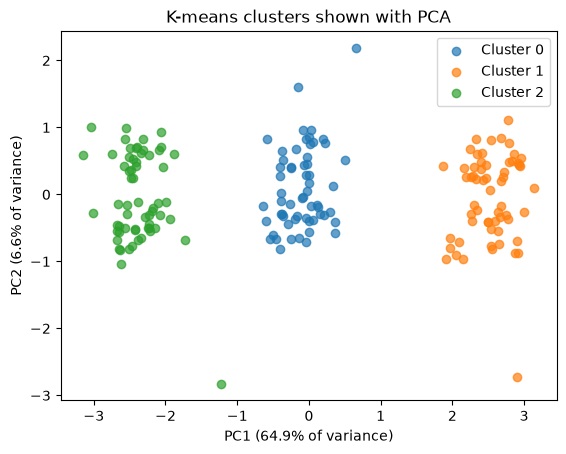

In [56]:

pca = PCA(n_components=2)
coords = pca.fit_transform(df_final)

plot_df = pd.DataFrame(coords, columns=["PC1", "PC2"])
plot_df["cluster"] = model.labels_

for cluster_id in sorted(plot_df["cluster"].unique()):
    group = plot_df[plot_df["cluster"] == cluster_id]
    plt.scatter(group["PC1"], group["PC2"], label=f"Cluster {cluster_id}", alpha=0.7)

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} of variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} of variance)")
plt.title("K-means clusters shown with PCA")
plt.legend()
plt.show()

Seeing details and patterns got from model 

In [57]:
results = df.copy()
results["cluster"] = model.labels_

results.groupby("cluster")[
    ["age", "annual_income_k", "spend_score",
     "visits_per_month", "avg_basket_value"]
].mean().round(1)

,age,annual_income_k,spend_score,visits_per_month,avg_basket_value
cluster,,,,,
0,38.4,59.9,53.3,5.2,76.2
1,52.4,102.4,82.9,8.0,145.7
2,22.9,29.6,25.0,1.9,39.3


Inspecting the silhouette score and inertia across multiple clusters 

In [58]:
for k in range(2,10):
    candidate = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = candidate.fit_predict(df_final)

    print(
        f"k={k}: "
        f"inertia={candidate.inertia_:.1f}, "
        f"silhouette={silhouette_score(df_final, labels):.3f}"
    )

k=2: inertia=572.9, silhouette=0.438
k=3: inertia=412.3, silhouette=0.367
k=4: inertia=387.3, silhouette=0.296
k=5: inertia=362.3, silhouette=0.231
k=6: inertia=329.5, silhouette=0.299
k=7: inertia=312.6, silhouette=0.199
k=8: inertia=284.8, silhouette=0.197
k=9: inertia=270.5, silhouette=0.212


Checking the models clusters to the actual data segment truth labels

In [59]:
check = pd.DataFrame({
    "cluster": model.labels_,
    "segment_truth": pd.read_csv("customer_behavior.csv")["segment_truth"]
})

pd.crosstab(check["cluster"], check["segment_truth"])

segment_truth,budget,premium,regular
cluster,,,
0,0,1,58
1,0,59,1
2,60,0,1


Another model with same parameters as before

In [60]:
model2 = KMeans(
    n_clusters=3,
    random_state=42,
    algorithm='lloyd',
    max_iter=500)

Trainned on only scaled numerical columns 

In [61]:
model2.fit(df_num_sca)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",500
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 5)","[

Used PCA again to get 2D plot 

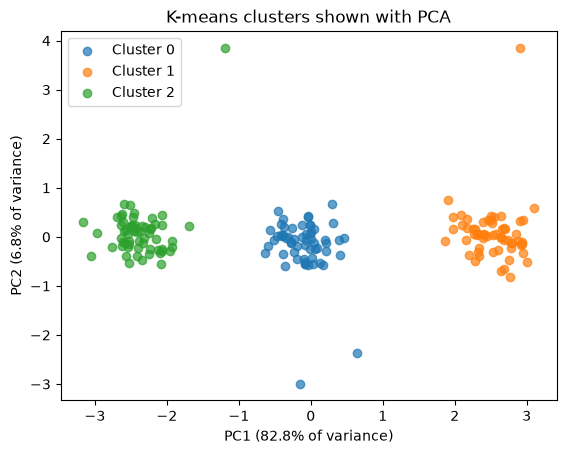

In [62]:

pca = PCA(n_components=2)
coords = pca.fit_transform(df_num_sca)

plot_df = pd.DataFrame(coords, columns=["PC1", "PC2"])
plot_df["cluster"] = model2.labels_

for cluster_id in sorted(plot_df["cluster"].unique()):
    group = plot_df[plot_df["cluster"] == cluster_id]
    plt.scatter(group["PC1"], group["PC2"], label=f"Cluster {cluster_id}", alpha=0.7)

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} of variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} of variance)")
plt.title("K-means clusters shown with PCA")
plt.legend()
plt.show()

Inspected the details of clusters of second model

In [63]:
results = df.copy()
results["cluster"] = model2.labels_

results.groupby("cluster")[
    ["age", "annual_income_k", "spend_score",
     "visits_per_month", "avg_basket_value"]
].mean().round(1)

,age,annual_income_k,spend_score,visits_per_month,avg_basket_value
cluster,,,,,
0,38.4,59.9,53.3,5.2,76.2
1,52.4,102.4,82.9,8.0,145.7
2,22.9,29.6,25.0,1.9,39.3


Checking second models clusters to segment truth of the dataset

In [64]:
check = pd.DataFrame({
    "cluster": model2.labels_,
    "segment_truth": pd.read_csv("customer_behavior.csv")["segment_truth"]
})

pd.crosstab(check["cluster"], check["segment_truth"])

segment_truth,budget,premium,regular
cluster,,,
0,0,1,58
1,0,59,1
2,60,0,1


Printing both models silhouette_score

In [65]:
print("With categories:", silhouette_score(df_final, model.labels_))
print("Numeric only:", silhouette_score(df_num_sca, model2.labels_))

With categories: 0.36747803528334183
Numeric only: 0.6195145469162218


Now taking linkage to comparision 

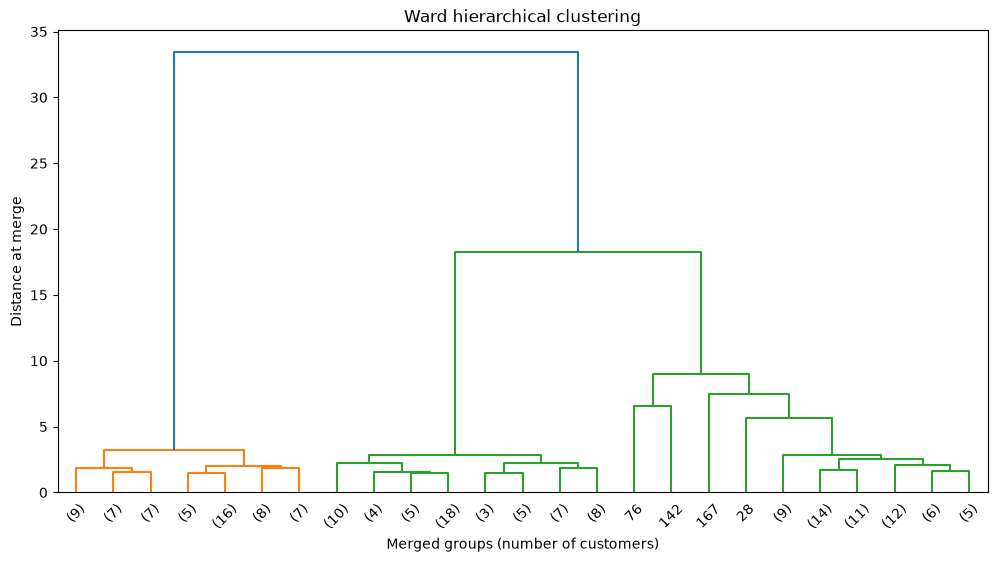

In [66]:
tree = linkage(df_num_sca, method="ward")

plt.figure(figsize=(12, 6))
dendrogram(tree, truncate_mode="lastp", p=25, show_leaf_counts=True)
plt.title("Ward hierarchical clustering")
plt.xlabel("Merged groups (number of customers)")
plt.ylabel("Distance at merge")
plt.show()

Seeing the score of Hierarchical models 

In [67]:
hier_model = AgglomerativeClustering(n_clusters=3, linkage="ward")
hier_labels = hier_model.fit_predict(df_num_sca)

print("Hierarchical silhouette:",
      silhouette_score(df_num_sca, hier_labels))

Hierarchical silhouette: 0.6205541421925489


Comparing the kmeans clusters with the hierarchical clusters 

In [68]:
pd.crosstab(
    pd.Series(model2.labels_, name="kmeans_cluster"),
    pd.Series(hier_labels, name="hierarchical_cluster")
)

hierarchical_cluster,0,1,2
kmeans_cluster,,,
0,59,0,0
1,1,59,0
2,1,0,60


Checking detials of hierarchical clusters

In [69]:
raw = pd.read_csv("customer_behavior.csv")
raw["hierarchical_cluster"] = hier_labels

raw.groupby("hierarchical_cluster")[
    ["age", "annual_income_k", "spend_score",
     "visits_per_month", "avg_basket_value"]
].mean().round(1)

,age,annual_income_k,spend_score,visits_per_month,avg_basket_value
hierarchical_cluster,,,,,
0,37.7,58.6,53.3,5.3,82.9
1,52.9,103.8,82.7,7.8,143.4
2,23.0,29.8,25.3,1.9,35.3


Checking the raw segment truth details with the model made clusters 

In [70]:
pd.crosstab(raw["hierarchical_cluster"], raw["segment_truth"])

segment_truth,budget,premium,regular
hierarchical_cluster,,,
0,0,1,60
1,0,59,0
2,60,0,0
